# Project 2: Predicting HDB Resale Prices

### Contents:
- [1. Background & Problem Statement](#1-background--problem-statement)
- [2.Data Import & Cleaning](#2-data-import-and-cleaning)
- [3. EDA](#3-exploratory-data-analysis)

----

## 1. Background & Problem Statement

### Background
Housing is often the most significant purchase that people make in their lifetime and property prices are a key concern for many individuals and families. The cost of housing can have a major impact on people's financial well-being and can affect their ability to achieve other important goals, such as saving for retirement, sending children to college or starting a business. 

With 80% of the population residing in HDB flats in Singapore, it is not surprising to see immense interest in understanding the resale price trends and the factors that impact flat value. Particularly in recent years, the issue of home affordability has increasingly come under the spotlight as HDB resale prices have risen by [**31.9% over the last 12 quarters**](https://www.straitstimes.com/singapore/housing/hdb-resale-prices-rise-09-in-q1-smallest-increase-in-last-10-quarters).

### Problem Statement

As a potential flat buyer, I would like to find out the **best price prediction model** that can be derived from a set of past HDB resale transaction data, so that I can use it as a guideline to understand the prices of different types of flats in different location. I would also be interested to know what are **the top factors that have significant influence on HDB resale flats.**, which will be very helpful to help me make a decision where to buy based on my needs and budget.

----

In [1]:
# Library Imports:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

## 2. Data Import and Cleaning

### Data Import

In [2]:
# Training data import:
hdb = pd.read_csv('../data/train.csv', low_memory=False)

### Data Summary

In [3]:
# Overview of the data:
def data_summary(df):
  with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print(f'Shape(row,col): {df.shape}')
    print('-'*60)
    print(f'Number of duplicates: {df.duplicated().sum()}')
    print('-'*60)
    print('Columns containing missing values:')
    isnull_df = pd.DataFrame(df.isnull().sum()).reset_index()
    isnull_df.columns = ['col','num_nulls']
    isnull_df['null_pct'] = (isnull_df['num_nulls']/len(df)).round(2)
    df_nullcheck = isnull_df[isnull_df['num_nulls']>0]
    if len(df_nullcheck) == 0:
      print('None')
    else:
      print(df_nullcheck)
    print('-'*60)
    print(f'Number of each unique datatypes:\n{df.dtypes.value_counts()}')
    print('-'*60)
    print(f'Number of unique values in each column and data types:')  
          
    # Create a DataFrame with column data types
    dtypes_df = pd.DataFrame(df.dtypes, columns=['Data Type'])

    # Create a DataFrame with number of unique values for each column
    unique_counts_df = pd.DataFrame(df.nunique(), columns=['Unique Values'])

    # Concatenate the two DataFrames
    summary_df = pd.concat([dtypes_df, unique_counts_df], axis=1).reset_index()
    
    print(summary_df)

data_summary(hdb)

Shape(row,col): (150634, 77)
------------------------------------------------------------
Number of duplicates: 0
------------------------------------------------------------
Columns containing missing values:
                      col  num_nulls  null_pct
45  Mall_Nearest_Distance        829      0.01
46       Mall_Within_500m      92789      0.62
47        Mall_Within_1km      25426      0.17
48        Mall_Within_2km       1940      0.01
50     Hawker_Within_500m      97390      0.65
51      Hawker_Within_1km      60868      0.40
52      Hawker_Within_2km      29202      0.19
------------------------------------------------------------
Number of each unique datatypes:
int64      32
float64    25
object     20
dtype: int64
------------------------------------------------------------
Number of unique values in each column and data types:
                        index Data Type  Unique Values
0                          id     int64         150634
1                resale_price   float64

**Comments:**  
* There are a total of 77 features (columns) and 150634 responses (rows) in the dataframe.  
* There are no duplicate values (columns/rows).
* There are a total of 7 columns with missing values. These columns are generally related to proximity to hawker centres or malls. Further examination will be done to determine the best way to treat the missing data.
* Further examination to be done on following columns with data types mismatch to determine best corrective action:

| #  | Column Name         | Dtype  | Number of unique values |
| -- | ------------------- | ------ | ----------------------- |
| 1  | tranc_yearmonth     | object | 110                     |
| 11 | tranc_year          | int64  | 10                      |
| 12 | tranc_month         | int64  | 12                      |
| 41 | postal              | object | 17483                   |
| 9  | lease_commence_date | int64  | 54                      |
| 22 | year_completed      | int64  | 59                      |

* There are some columns which seem to be repetitive/redundant, for example, 'mid' = middle value of storey range where the sold flat is located and 'mid_storey' = median value storey range where the sold flat is located, and many more. These columns will be identified in the later section to determine which course of action to take.

### Data Cleaning

**Change column names to all lower case first for ease of convenience:**

In [4]:
hdb.columns = hdb.columns.str.lower()
hdb.head()

,id,resale_price,tranc_yearmonth,tranc_year,tranc_month,town,planning_area,block,street_name,address,...,vacancy,pri_sch_affiliation,pri_sch_latitude,pri_sch_longitude,sec_sch_nearest_dist,sec_sch_name,cutoff_point,affiliation,sec_sch_latitude,sec_sch_longitude
0,88471,680000.0,2016-05,2016,5,KALLANG/WHAMPOA,Kallang,3B,UPP BOON KENG RD,"3B, UPP BOON KENG RD",...,78,1,1.317659,103.882504,1138.633422,Geylang Methodist School,224,0,1.317659,103.882504
1,122598,665000.0,2012-07,2012,7,BISHAN,Bishan,153,BISHAN ST 13,"153, BISHAN ST 13",...,45,1,1.349783,103.854529,447.894399,Kuo Chuan Presbyterian Secondary School,232,0,1.350110,103.854892
2,170897,838000.0,2013-07,2013,7,BUKIT BATOK,Bukit Batok,289B,BT BATOK ST 25,"289B, BT BATOK ST 25",...,39,0,1.345245,103.756265,180.074558,Yusof Ishak Secondary School,188,0,1.342334,103.760013
3,86070,550000.0,2012-04,2012,4,BISHAN,Bishan,232,BISHAN ST 22,"232, BISHAN ST 22",...,20,1,1.354789,103.844934,389.515528,Catholic High School,253,1,1.354789,103.844934
4,153632,298000.0,2017-12,2017,12,YISHUN,Yishun,876,YISHUN ST 81,"876, YISHUN ST 81",...,74,0,1.416280,103.838798,312.025435,Orchid Park Secondary School,208,0,1.414888,103.838335


#### Data Type Mismatch

**Mixed Data Type Within Column**

In [5]:
# Convert mixed dtype 'postal' column to numeric values:

hdb['postal'] = pd.to_numeric(hdb['postal'], errors='coerce')

# Find the rows that contain the unknown string value
unknown_values = hdb[hdb['postal'].isna()]

# Percentage of rows with unknown values in 'postal' column:
print (f'Percentage of rows with unknown values in postal column: {round(len(unknown_values)/len(hdb)*100,2)}%')

Percentage of rows with unknown values in postal column: 0.02%


**Comments**

As seen above, there is a small percentage of 0.02% of string type of values mixed within the 'postal' column. Considering that there are already other seemingly more important features such as 'Town' and 'Planning Area' to account for the location factor on HDB resale prices, the Postal column should not make significant impact on the flat price and hence will be dropped.

In [6]:
# Drop the postal column:
hdb.drop('postal', axis=1, inplace=True)

hdb.shape # check if column has been dropped

(150634, 76)

#### Columns with Missing Values

To recap, here are the columns with missing data that require further work:

<img src="../images/missing_value_cols.png" style="width: 50%; height: auto;">

**Columns related to proximity to malls**

In [7]:
# Examine rows with missing values in columns related to proximity to malls:

# create a df containing the 4 columns related to proximity to malls:
malls_df = hdb[['mall_nearest_distance', 'mall_within_500m','mall_within_1km', 'mall_within_2km']]

# Examine rows with missing values in the 'mall_nearest_distance' column:
malls_df[malls_df['mall_nearest_distance'].isna()]

,mall_nearest_distance,mall_within_500m,mall_within_1km,mall_within_2km
75,NaN,NaN,NaN,NaN
321,NaN,NaN,NaN,NaN
478,NaN,NaN,NaN,NaN
643,NaN,NaN,NaN,NaN
691,NaN,NaN,NaN,NaN
...,...,...,...,...
150296,NaN,NaN,NaN,NaN
150388,NaN,NaN,NaN,NaN
150394,NaN,NaN,NaN,NaN
150479,NaN,NaN,NaN,NaN


**Comments**

The missing values in the 'mall_nearest_distance' could be due to the nearest mall to that particular resale flat being further than 2 km (these rows are also missing values in the other 3 related columns as seen above). 

In [8]:
# Examine if it is the case that the missing values in the 'mall_nearest_distance' column are due to the absence of malls in the vicinity:
# min-max range of the 'mall_nearest_distance' column:
print (f'Min. to max values of mall_nearest_distance column: {malls_df["mall_nearest_distance"].min()} - {malls_df["mall_nearest_distance"].max()}')

Min. to max values of mall_nearest_distance column: 0.0 - 3496.40291


In [9]:
# Examine rows with values greater than 2km in the 'mall_nearest_distance' column:
malls_df[malls_df['mall_nearest_distance']>2000]

,mall_nearest_distance,mall_within_500m,mall_within_1km,mall_within_2km
109,2050.201309,NaN,NaN,NaN
220,2247.327448,NaN,NaN,NaN
662,2218.607002,NaN,NaN,NaN
672,2038.439070,NaN,NaN,NaN
798,2115.704584,NaN,NaN,NaN
...,...,...,...,...
149097,2103.873021,NaN,NaN,NaN
149446,2218.607002,NaN,NaN,NaN
149450,2260.225191,NaN,NaN,NaN
150095,2007.777071,NaN,NaN,NaN


**Comments**

* There are 1111 rows of data with the nearest mall to the resale flat further than 2km and yet contained values in the mall_nearest_distance column. This is inconsistent with the rows with missing values in the mall_nearest_distance column. 
* Another possible explanation for this is because the nearested mall is further than the maximum value recorded in this column (i.e. 3.496 km), hence no values have been recorded for these rows of data. 
* Considering that amenities can have some impact on the resale flat value and mall is a key component of amenities, let's assume that the nearest mall to these resale flats are 3.5km and fill these cells with this value.

In [10]:
# Fill rows with missing values in the 'mall_nearest_distance' column with 3500 (3.5km):
hdb['mall_nearest_distance'] = hdb['mall_nearest_distance'].fillna(3500)

# Create a new column 'mall_within_3.5km' to indicate if there is a mall between 2.0 and 3.5km:
hdb['mall_within_3.5km'] = np.where(hdb['mall_nearest_distance'].between(2001,3500), 1, 0)

# print rows with values between 2 and 3.5 km in the 'mall_nearest_distance' column:
hdb[hdb['mall_nearest_distance'].between(2001,3500)]

,id,resale_price,tranc_yearmonth,tranc_year,tranc_month,town,planning_area,block,street_name,address,...,pri_sch_affiliation,pri_sch_latitude,pri_sch_longitude,sec_sch_nearest_dist,sec_sch_name,cutoff_point,affiliation,sec_sch_latitude,sec_sch_longitude,mall_within_3.5km
75,163384,455000.0,2021-04,2021,4,SENGKANG,Sengkang,468A,FERNVALE LINK,"468A, FERNVALE LINK",...,0,1.397621,103.880210,789.399776,Pei Hwa Secondary School,219,0,1.390380,103.878593,1
109,156373,510000.0,2013-01,2013,1,BEDOK,Bedok,601,BEDOK RESERVOIR RD,"601, BEDOK RESERVOIR RD",...,0,1.330913,103.911349,1075.003159,Ping Yi Secondary School,189,0,1.327140,103.920836,1
220,85651,370000.0,2014-08,2014,8,BEDOK,Bedok,123,BEDOK RESERVOIR RD,"123, BEDOK RESERVOIR RD",...,0,1.330913,103.911349,1093.318715,Manjusri Secondary School,188,0,1.327520,103.901811,1
321,163733,495000.0,2021-03,2021,3,CHOA CHU KANG,Choa Chu Kang,815C,CHOA CHU KANG AVE 7,"815C, CHOA CHU KANG AVE 7",...,0,1.381767,103.747290,926.560287,Chua Chu Kang Secondary School,211,0,1.383275,103.752025,1
478,68334,425000.0,2021-02,2021,2,GEYLANG,Geylang,18B,CIRCUIT RD,"18B, CIRCUIT RD",...,1,1.326511,103.881757,1366.262344,Bartley Secondary School,188,0,1.340017,103.882455,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150337,115406,385000.0,2019-01,2019,1,BEDOK,Bedok,120,BEDOK RESERVOIR RD,"120, BEDOK RESERVOIR RD",...,0,1.330913,103.911349,976.410224,Manjusri Secondary School,188,0,1.327520,103.901811,1
150388,163799,690000.0,2021-02,2021,2,PUNGGOL,Punggol,676C,PUNGGOL DR,"676C, PUNGGOL DR",...,0,1.404409,103.910996,391.955268,Punggol Secondary School,194,0,1.402126,103.909119,1
150394,163287,518000.0,2021-01,2021,1,PUNGGOL,Punggol,678A,PUNGGOL DR,"678A, PUNGGOL DR",...,0,1.404409,103.910996,395.677442,Punggol Secondary School,194,0,1.402126,103.909119,1
150479,163674,515000.0,2021-04,2021,4,PUNGGOL,Punggol,677B,PUNGGOL DR,"677B, PUNGGOL DR",...,0,1.404409,103.910996,362.688469,Punggol Secondary School,194,0,1.402126,103.909119,1


In [11]:
# Add 0 to rows with missing values in 'malls_within_500m', 'malls_within_1km' and 'malls_within_2km' columns:
hdb.fillna({'mall_within_500m': 0, 'mall_within_1km': 0, 'mall_within_2km': 0}, inplace=True)

# Check if there are still missing values in the columns related to proximity to malls:
hdb[['mall_nearest_distance', 'mall_within_500m','mall_within_1km', 'mall_within_2km', 'mall_within_3.5km']].isnull().sum()

mall_nearest_distance    0
mall_within_500m         0
mall_within_1km          0
mall_within_2km          0
mall_within_3.5km        0
dtype: int64

**Columns related to proximity to hawker centres**

In [12]:
# Apply similar logic to examine columns related to proximity to hawker centres:

# create a df containing the 4 columns related to proximity to malls:
hawker_df = hdb[['hawker_nearest_distance', 'hawker_within_500m','hawker_within_1km', 'hawker_within_2km']]

# Examine rows with missing values in the 'hawker_within_2km' column:
hawker_df[hawker_df['hawker_within_2km'].isna()]

,hawker_nearest_distance,hawker_within_500m,hawker_within_1km,hawker_within_2km
26,2028.864896,NaN,NaN,NaN
27,2044.044484,NaN,NaN,NaN
30,3472.690804,NaN,NaN,NaN
31,2278.363660,NaN,NaN,NaN
33,3159.026726,NaN,NaN,NaN
...,...,...,...,...
150615,4612.654746,NaN,NaN,NaN
150620,3794.986446,NaN,NaN,NaN
150623,2537.537184,NaN,NaN,NaN
150625,4491.675680,NaN,NaN,NaN


In [13]:
# Examine the min-max values in the 'hawker_nearest_distance' column:
print (f'Min. to max values of hawker_nearest_distance column: {hawker_df["hawker_nearest_distance"].min()} - {hawker_df["hawker_nearest_distance"].max()}')

Min. to max values of hawker_nearest_distance column: 1.873295478 - 4907.036414


**Comments**

* There are 29202 rows of data with the nearest hawker centre to the resale flat further than 2km. 
* These rows are missing values because there is no hawker centre within the designated distance to the resale flat.
* Hence, 0 should be added to these missing values. Considering there is a considerable number of flats with the nearest hawker centre further than 2km, these data should be reflected in a new column

In [14]:
# Add 0 to rows with missing values in 'hawker_within_500m', 'hawker_within_1km' and 'hawker_within_2km' columns:
hdb.fillna({'hawker_within_500m': 0, 'hawker_within_1km': 0, 'hawker_within_2km': 0}, inplace=True)

# Check if there are still missing values in the columns related to proximity to hawker centres:
hdb[['hawker_within_500m', 'hawker_within_1km', 'hawker_within_2km']].isnull().sum()

hawker_within_500m    0
hawker_within_1km     0
hawker_within_2km     0
dtype: int64

In [15]:
# Create a new column 'hawker_within_5km' to indicate if there is a hawker centre between 2.0 and 5.0km:
hdb['hawker_within_5km'] = np.where(hdb['hawker_nearest_distance'].between(2001,5000), 1, 0)

# print rows with values between 2 and 5 km in the 'hawker_nearest_distance' column:
hdb[hdb['hawker_nearest_distance'].between(2001,5000)]

,id,resale_price,tranc_yearmonth,tranc_year,tranc_month,town,planning_area,block,street_name,address,...,pri_sch_latitude,pri_sch_longitude,sec_sch_nearest_dist,sec_sch_name,cutoff_point,affiliation,sec_sch_latitude,sec_sch_longitude,mall_within_3.5km,hawker_within_5km
26,166009,453000.0,2019-08,2019,8,JURONG WEST,Jurong West,653A,JURONG WEST ST 61,"653A, JURONG WEST ST 61",...,1.336643,103.699683,633.528960,Jurong West Secondary School,199,0,1.335256,103.702098,0,1
27,69679,360000.0,2020-06,2020,6,BUKIT BATOK,Bukit Batok,291A,BT BATOK ST 24,"291A, BT BATOK ST 24",...,1.345245,103.756265,464.674132,Yusof Ishak Secondary School,188,0,1.342334,103.760013,0,1
30,116245,383000.0,2016-03,2016,3,CHOA CHU KANG,Choa Chu Kang,417,CHOA CHU KANG AVE 4,"417, CHOA CHU KANG AVE 4",...,1.377743,103.741861,393.733430,Bukit Panjang Government High School,244,0,1.382137,103.738134,0,1
31,108393,503000.0,2012-11,2012,11,SEMBAWANG,Sembawang,507C,WELLINGTON CIRCLE,"507C, WELLINGTON CIRCLE",...,1.451934,103.822321,1013.080578,Canberra Secondary School,188,0,1.453280,103.814471,0,1
33,113435,496000.0,2012-07,2012,7,SENGKANG,Sengkang,299B,COMPASSVALE ST,"299B, COMPASSVALE ST",...,1.394530,103.897865,161.155684,Compassvale Secondary School,210,0,1.396218,103.899872,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150615,65967,375588.0,2020-01,2020,1,PUNGGOL,Punggol,667A,PUNGGOL DR,"667A, PUNGGOL DR",...,1.400009,103.913072,541.936555,Punggol Secondary School,194,0,1.402126,103.909119,0,1
150620,165527,450000.0,2020-10,2020,10,PUNGGOL,Punggol,175D,PUNGGOL FIELD,"175D, PUNGGOL FIELD",...,1.400298,103.907431,433.310536,Punggol Secondary School,194,0,1.402126,103.909119,0,1
150623,171210,527000.0,2012-07,2012,7,SENGKANG,Sengkang,260C,SENGKANG EAST WAY,"260C, SENGKANG EAST WAY",...,1.394530,103.897865,544.133020,Compassvale Secondary School,210,0,1.396218,103.899872,0,1
150625,163670,715000.0,2021-04,2021,4,PUNGGOL,Punggol,676B,PUNGGOL DR,"676B, PUNGGOL DR",...,1.404409,103.910996,330.498161,Punggol Secondary School,194,0,1.402126,103.909119,1,1


#### Check for Other Issues - repetitive, redundant, data value mismatch, etc.

The columns will be analyzed based on properties that can be grouped as follows:
1) Transaction period 
2) Flat size and layout
3) Flat age 
4) Location 
5) Amenities
6) Block Layout
7) Transport
8) School
9) Others

#### 1) Transaction period
Recap: the columns related to transaction period are
| #  | Column Name         | Dtype  | Number of unique values |
| -- | ------------------- | ------ | ----------------------- |
| 1  | tranc_yearmonth     | object | 110                     |
| 11 | tranc_year          | int64  | 10                      |
| 12 | tranc_month         | int64  | 12                      |

'tranc_yearmonth' can be dropped since there are already year and month columns.

In [16]:
# Drop tranc_yearmonth
hdb.drop('tranc_yearmonth', axis=1, inplace=True)

#### 2) Flat size and layout
The relevant columns are:
| Column Name     | Dtype   | No. of unique values | Column Description                                          |
| --------------- | ------- | -------------------- | ----------------------------------------------------------- |
| floor_area_sqm  | float64 | 169                  |  floor area of the resale flat unit in square metres        |
| floor_area_sqft | float64 | 169                  |  floor area of the resale flat unit in square feet          |
| full_flat_type  | object  | 43                   |  combination of flat_type and flat_model                    |
| flat_type       | object  | 7                    |  type of the resale flat unit, e.g. 3 ROOM                  |
| flat_model      | object  | 20                   |  HDB model of the resale flat, e.g. Multi Generation        |
| storey_range    | object  | 25                   |  floor level (range) of the resale flat unit, e.g. 07 TO 09 |
| mid_storey      | int64   | 22                   |  median value of storey_range                               |
| lower           | int64   | 22                   |  lower value of storey_range                                |
| upper           | int64   | 23                   |  upper value of storey_range                                |
| mid             | int64   | 22                   |  middle value of storey_range                               |
| max_floor_lvl   | int64   | 41                   |  highest floor of the resale flat                           |

**Comments**
* **'floor_area_sqm'** will be dropped because there is already a column recording the square feet of the flat and square feet unit metric is more commonly used in Singapore.
* **'full_flat_type'** will be dropped because the values in it are merely combination of two other columns namely 'flat_model' and 'flat_type'.
* **'mid_storey'** will be dropped because it is exactly the same column as the 'mid' column. Both columns showed that the mid value of the storey range where the resale flat is located. Further examination will be made on other columns related to the storey range of the resale flat to determine if additional data cleaning is required

In [17]:
hdb.drop(['floor_area_sqm', 'full_flat_type', 'mid_storey'], axis=1, inplace=True)

hdb.shape # check if column has been dropped

(150634, 74)

**Columns related to storey range of resale flats**

In [18]:
# Examine columns related to storey range of resale flats:
storey_df = hdb[['storey_range', 'lower', 'mid','upper']]
storey_df.head()

,storey_range,lower,mid,upper
0,10 TO 12,10,11,12
1,07 TO 09,7,8,9
2,13 TO 15,13,14,15
3,01 TO 05,1,3,5
4,01 TO 03,1,2,3


**Comments**

* From the snapshot above, it can be seen that 'lower', 'mid' and 'upper' are simply a split of text-based 'storey_range' column into 3 separate numerical variable columns. These values are not helpful in indicating if the flat is a low-, mid- or high-rise unit, which can be a key factor affecting the flat value. 
* As no specific floor unit is provided in the data set, the mid/median value of the storey range of the resale flat will be used to determine if the flat is low-, mid- or high-rise unit.

In [19]:
# Get the range of values in the 'mid' column:
print (f'Min. to max values of mid column: {storey_df["mid"].min()} - {storey_df["mid"].max()}')

Min. to max values of mid column: 2 - 50


In [20]:
# Get the unique value counts in the 'max_floor_lvl' column in ascending order:
hdb['max_floor_lvl'].value_counts().sort_index()

2       132
3        58
4      4382
5        78
6        57
7        43
8       920
9      2940
10     8473
11     9580
12    34192
13    16975
14     8225
15     9183
16    18663
17     8004
18     4872
19     2055
20     2491
21     1698
22     2098
23      544
24     1044
25     5262
26      668
27      654
28      585
29      193
30     3096
31       70
33        4
34       55
35       95
36       54
38      141
40     2366
42      111
43      107
47       92
48        5
50      369
Name: max_floor_lvl, dtype: int64

**Comments**

* As seen above, there are some HDB blocks that are low-rise by design (2 - 4 floors in total). 
* The following definitions will be used to categorize the flats accordingly:
    - If the max_floor_lvl is <= 4, the flat will be categorized as low;
    - If the max_floor_lvl is between 5 and 7, the flat will be categorized as low and mid based on 50% cutoff;
    - If the max_floor_lvl is 8 and above, the flat will be categorized as low , mid  and high based on 33.33% and 66.67% cutoff.

In [21]:
# Rename columns for better readability:

# Rename 'mid' column to 'flat_floor':
hdb.rename(columns={'mid': 'flat_floor'}, inplace=True)

# Rename 'max_floor_lvl' column to 'total_floor':
hdb.rename(columns={'max_floor_lvl': 'total_floor'}, inplace=True)

In [22]:
def floor_category(df):
    flat_position = []
    for index, row in df.iterrows():
        if row['total_floor'] <= 4:
            flat_position.append('low')
        elif row['total_floor'] >= 5 and row['total_floor'] <= 7:
                if row['flat_floor']/row['total_floor'] <= 0.50:
                    flat_position.append('low')
                else:
                    flat_position.append('mid')
        else:
            if row['total_floor'] >= 8:
                if row['flat_floor']/row['total_floor'] <= 0.333:
                    flat_position.append('low')
                elif row['flat_floor']/row['total_floor'] > 0.333 and row['flat_floor']/row['total_floor'] <= 0.667:
                    flat_position.append('mid')
                else:
                    flat_position.append('high')
    return flat_position

# apply the function to the hdb df:
hdb['flat_position'] = floor_category(hdb)

# Print the relevant columns to check if the function has been applied correctly:
hdb[['flat_floor', 'total_floor', 'flat_position']].head()

,flat_floor,total_floor,flat_position
0,11,25,mid
1,8,9,high
2,14,16,high
3,3,11,low
4,2,4,low


In [23]:
# Drop all other unrequired columns related to storey range:
hdb.drop(['storey_range', 'lower', 'upper'], axis=1, inplace=True)

hdb.shape # check if columns have been dropped

(150634, 72)

#### 3) Flat age
The relevant columns are:
| Column Name         | Dtype | No. of unique values | Column Description                                        |
| ------------------- | ----- | -------------------- | --------------------------------------------------------- |
| lease_commence_date | int64 | 54                   |  commencement year of the flat unit's 99-year lease       |
| hdb_age             | int64 | 54                   |  number of years from lease_commence_date to present year |
| year_completed      | int64 | 59                   |  year which construction was completed for resale flat    |

In [24]:
# Examine some values in these three columns:
hdb[['lease_commence_date', 'hdb_age', 'year_completed']].head()

,lease_commence_date,hdb_age,year_completed
0,2006,15,2005
1,1987,34,1987
2,1997,24,1996
3,1992,29,1990
4,1987,34,1987


**Comments**
* **'lease_commence_date** and **'year_completed** can be dropped because these two columns are essentially indication of the property age, which is already captured in the'hdb_age' column.

In [25]:
hdb.drop(['lease_commence_date','year_completed'], axis=1, inplace=True)

hdb.shape # check if columns have been dropped

(150634, 70)

#### 4) Location
The relevant columns are:
| Column Name   | Dtype   | No. of unique values | Column Description                                              |
| ------------- | ------- | -------------------- | --------------------------------------------------------------- |
| town          | object  | 26                   |  HDB township where the flat is located, e.g. BUKIT MERAH       |
| planning_area | object  | 32                   |  Government planning area that the flat is located              |
| block         | object  | 2514                 |  block number of the resale flat, e.g. 454                      |
| street_name   | object  | 553                  |  street name where the resale flat resides, e.g. TAMPINES ST 42 |
| address       | object  | 9157                 |  combination of block and street_name                           |
| latitude      | float64 | 9126                 |  Latitude based on postal code                                  |
| longitude     | float64 | 9098                 |  Longitude based on postal code                                 |

**Comments**
* **planning_area** can be dropped because it is highly overlapped with 'town' and not intuitive for most people who know the geography of Singapore
* **block** can be dropped because it is already reflected in 'address' column.
* **street_name** and **address** will be kept for now as it is difficult to determine which one is more useful at the moment.
* **latitude** and **longtitude** columns do not provide much value add but distance to a certain point can be derived from these values, further examination to be made to decide next step

In [26]:
hdb.drop(['planning_area','block'], axis=1, inplace=True)

hdb.shape # check if columns have been dropped

(150634, 68)

**Latitude and Longtitude**
* It is no secret that location plays a huge impact on housing value. In general, HDB flats located [near to the city centre](https://sg.news.yahoo.com/hdb-resale-flat-estates-ranked-200452731.html#:~:text=The%20Central%20area%20is%20generally,well%2Dconnected%20to%20the%20city.) fetch the highest price.  Hence, it could be useful to include this piece of information in the data set. 
* Distance from and to a certain point can be derived from the coordinates of the location.
* The [Raffles Place MRT station](https://goo.gl/maps/TYrTXE9oidwXM7oT9) will be assumed as the city centre location for ease of calculation.

In [27]:
# Calculate the distance between each resale flat and Raffles Place MRT station:

def haversine(lat1, lon1, lat2, lon2):
    # convert decimal degrees to radians
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])

    # haversine formula
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    r = 6371 * 1000  # Radius of earth in meters
    return c * r

# Define the coordinates of Raffles Place MRT station
rp_lat, rp_lon = 1.2838742,103.8489138 # copied from Google Maps

# Calculate the distance between each apartment and Raffles Place MRT station
hdb['distance_to_city'] = haversine(hdb['latitude'], hdb['longitude'], rp_lat, rp_lon)

# Print 10 rows to check:
hdb[['street_name', 'latitude', 'longitude', 'distance_to_city']].head(10)

,street_name,latitude,longitude,distance_to_city
0,UPP BOON KENG RD,1.314299,103.872828,4302.621315
1,BISHAN ST 13,1.346086,103.855078,6951.492045
2,BT BATOK ST 25,1.343867,103.760535,11875.402672
3,BISHAN ST 22,1.358245,103.845504,8278.356973
4,YISHUN ST 81,1.414745,103.835532,14627.984371
5,ALJUNIED CRES,1.321703,103.886196,5905.132783
6,HOUGANG AVE 8,1.371276,103.880059,10316.923696
7,BEDOK RESERVOIR RD,1.337642,103.918906,9812.472741
8,SIN MING AVE,1.358356,103.830398,8533.897076
9,ANCHORVALE RD,1.390299,103.886489,12549.452718


In [28]:
# Drop all columns related to latitude and longitude as they are no longer needed:

# Select columns containing 'latitude' and 'longitude'
cols_to_drop = hdb.filter(like='latitude').columns.tolist() + hdb.filter(like='longitude').columns.tolist()

# Drop selected columns
hdb = hdb.drop(columns=cols_to_drop)

hdb.shape

(150634, 59)

#### 5) Amenities
The remaining "uncleaned" relevant columns are:
| Column Name             | Dtype   | No. of unique values | Column Description                                                            |
| ----------------------- | ------- | -------------------- | ----------------------------------------------------------------------------- |
| multistorey_carpark     | object  | 2                    |  boolean value if resale flat has a multistorey carpark in the same block     |
| precinct_pavilion       | object  | 2                    |  boolean value if resale flat has a pavilion in the same block                |
| market_hawker           | object  | 2                    |  boolean value if resale flat has a market or hawker centre in the same block |
| hawker_food_stalls      | int64   | 52                   |  number of hawker food stalls in the nearest hawker centre                    |
| hawker_market_stalls    | int64   | 70                   |  number of hawker and market stalls in the nearest hawker centre              |
| commercial              | object  | 2                    |  boolean value if resale flat has commercial units in the same block          |

**Comments**
* Several relevant columns are omitted here as these are already cleaned due to missing values.
* Majority of remaining columns are of boolean nature, hence further examination will be made in conjunction with other boolean columns in other categories

**Columns with boolean type of values**

According to the [dataset description](https://www.kaggle.com/competitions/dsi-sg-project-2-regression-challenge-hdb-price/data) provided, the following columns contain boolean values:

| Column Name         | Non-Null | Count    | Dtype  | Column Description                                                               |
| ------------------- | -------- | -------- | ------ | -------------------------------------------------------------------------------- |
| mrt_interchange     | 150634   | non-null | int64  |  boolean value if the nearest MRT station is a train interchange station         |
| bus_interchange     | 150634   | non-null | int64  |  boolean value if the nearest MRT station is also a bus interchange              |
| commercial          | 150634   | non-null | object |  boolean value if resale flat has commercial units in the same block             |
| market_hawker       | 150634   | non-null | object |  boolean value if resale flat has a market or hawker centre in the same block    |
| affiliation         | 150634   | non-null | int64  |  boolean value if the nearest secondary school has an primary school affiliation |
| pri_sch_affiliation | 150634   | non-null | int64  |  boolean value if the nearest primary school has a secondary school affiliation  |
| multistorey_carpark | 150634   | non-null | object |  boolean value if resale flat has a multistorey carpark in the same block        |
| precinct_pavilion   | 150634   | non-null | object |  boolean value if resale flat has a pavilion in the same block                   |

As seen above, the data type of each boolean column is inconsistent, i.e. some contain '1 and 0' while some contain string response. Further examination will be made on the latter to determine cleaning action.

In [29]:
# Rename some columns for better readability:
hdb.rename(columns={'commercial': 'have_shops', 'market_hawker': 'have_mkt_hawker', 'affiliation':'affiliation_to_pri', 'pri_sch_affiliation': 'affiliation_to_sec', 'multistorey_carpark': 'have_multi_carpark', 'precinct_pavilion': 'have_pavilion'}, inplace=True)

In [30]:
# See what are the unique values of each of the boolean columns:
bool_df = hdb[['mrt_interchange', 'bus_interchange', 'affiliation_to_pri', 'affiliation_to_sec', 'have_shops', 'have_mkt_hawker', 'have_multi_carpark', 'have_pavilion']]

for col in bool_df.columns:
    print (f'Unique values in {col} column: {bool_df[col].unique()}')

Unique values in mrt_interchange column: [0 1]
Unique values in bus_interchange column: [0 1]
Unique values in affiliation_to_pri column: [0 1]
Unique values in affiliation_to_sec column: [1 0]
Unique values in have_shops column: ['N' 'Y']
Unique values in have_mkt_hawker column: ['N' 'Y']
Unique values in have_multi_carpark column: ['N' 'Y']
Unique values in have_pavilion column: ['N' 'Y']


In [31]:
# Convert boolean columns containing 'Y' and 'N' to 1 and 0:
string_value_bool = hdb[['have_shops', 'have_mkt_hawker', 'have_multi_carpark', 'have_pavilion']]

for col in string_value_bool.columns:
    hdb[col] = np.where(hdb[col] == 'Y', 1, 0)

# print the columns to check if the conversion has been done correctly:
hdb[['have_shops', 'have_mkt_hawker', 'have_multi_carpark', 'have_pavilion']].head()

,have_shops,have_mkt_hawker,have_multi_carpark,have_pavilion
0,0,0,0,0
1,0,0,0,0
2,0,0,0,0
3,1,0,0,0
4,0,0,0,0


#### 6) Block Layout
The remaining "uncleaned" relevant columns are:
| Column Name           | Dtype | No. of unique values | Column Description                                                            |
| --------------------- | ----- | -------------------- | ----------------------------------------------------------------------------- |
| total_dwelling_units  | int64 | 320                  |  total number of residential dwelling units in the resale flat                |
| 1room_sold            | int64 | 2                    |  number of 1-room residential units in the resale flat                        |
| 2room_sold            | int64 | 99                   |  number of 2-room residential units in the resale flat                        |
| 3room_sold            | int64 | 255                  |  number of 3-room residential units in the resale flat                        |
| 4room_sold            | int64 | 200                  |  number of 4-room residential units in the resale flat                        |
| 5room_sold            | int64 | 133                  |  number of 5-room residential units in the resale flat                        |
| exec_sold             | int64 | 103                  |  number of executive type residential units in the resale flat block          |
| multigen_sold         | int64 | 7                    |  number of multi-generational type residential units in the resale flat block |
| studio_apartment_sold | int64 | 61                   |  number of studio apartment type residential units in the resale flat block   |
| 1room_rental          | int64 | 11                   |  number of 1-room rental residential units in the resale flat block           |
| 2room_rental          | int64 | 48                   |  number of 2-room rental residential units in the resale flat block           |
| 3room_rental          | int64 | 15                   |  number of 3-room rental residential units in the resale flat block           |
| other_room_rental     | int64 | 3                    |  number of "other" type rental residential units in the resale flat block     |

**Comments**
* The number of unique values in 1room_sold and other_room_rental are relatively insignificant, hence further examination will be made to determine if these columns can be dropped

In [32]:
# Counts of each unique value in:
hdb['1room_sold'].value_counts()

0      150552
255        82
Name: 1room_sold, dtype: int64

In [33]:
hdb['other_room_rental'].value_counts()

0    150602
2        19
1        13
Name: other_room_rental, dtype: int64

Proceed to drop the two columns as results shown a large majority of responses are zero.

In [34]:
hdb.drop(['1room_sold', 'other_room_rental'], axis=1, inplace=True)

hdb.shape # check if columns have been dropped

(150634, 57)

#### 7) Transport
The remaining "uncleaned" relevant columns are:
| Column Name               | Dtype   | No. of unique values | Column Description                                                       |
| ------------------------- | ------- | -------------------- | ------------------------------------------------------------------------ |
| mrt_nearest_distance      | float64 | 9126                 |  distance (in metres) to the nearest MRT station                         |
| mrt_name                  | object  | 94                   |  name of the nearest MRT station                                         |
| bus_stop_nearest_distance | float64 | 9126                 |  distance (in metres) to the nearest bus stop                            |
| bus_stop_name             | object  | 1657                 |  name of the nearest bus stop                                            |

**Comments**
* No actions to be taken for now

#### 8) School
The remaining "uncleaned" relevant columns are:
| Column Name              | Dtype   | No. of unique values | Column Description                                    |
| ------------------------ | ------- | -------------------- | ----------------------------------------------------- |
| pri_sch_name             | object  | 177                  |  name of the nearest primary school                   |
| vacancy                  | int64   | 66                   |  number of vacancies in the nearest primary school    |
| sec_sch_nearest_dist     | float64 | 9126                 |  distance (in metres) to the nearest secondary school |
| sec_sch_name             | object  | 134                  |  name of the nearest secondary school                 |
| cutoff_point             | int64   | 54                   |  PSLE cutoff point of the nearest secondary school    |
| pri_sch_nearest_distance | float64 | 9126                 |  distance (in metres) to the nearest primary school   |

**Comments**
* Rename 'vacancy' and 'cutoff_point" for better readability

In [35]:
# Rename some columns for better readability:
hdb.rename(columns={'vacancy': 'pri_sch_vacancy', 'cutoff_point': 'psle_cutoff'}, inplace=True)

#### 9) Others
The remaining columns are:
| Column Name | Dtype  | No. of unique values | Column Description                                                    |
| ----------- | ------ | -------------------- | --------------------------------------------------------------------- |
| residential | object | 1                    |  boolean value if resale flat has residential units in the same block |
| id          | int64  | 150634               | ID of the resale transaction                                          |

**Comments**
* residential is redundant as there is only 1 value although it is of boolean nature

In [36]:
hdb.drop(['residential'], axis=1, inplace=True)

hdb.shape # check if columns have been dropped

(150634, 56)

## 3. Exploratory Data Analysis

In [37]:
# Use data summary function defined earlier to review current state of the dataset:
data_summary(hdb)

Shape(row,col): (150634, 56)
------------------------------------------------------------
Number of duplicates: 0
------------------------------------------------------------
Columns containing missing values:
None
------------------------------------------------------------
Number of each unique datatypes:
int64      31
float64    15
object     10
dtype: int64
------------------------------------------------------------
Number of unique values in each column and data types:
                        index Data Type  Unique Values
0                          id     int64         150634
1                resale_price   float64           3295
2                  tranc_year     int64             10
3                 tranc_month     int64             12
4                        town    object             26
5                 street_name    object            553
6                     address    object           9157
7             floor_area_sqft   float64            169
8                  flat_m

**Correlation of variables to HDB resale price**

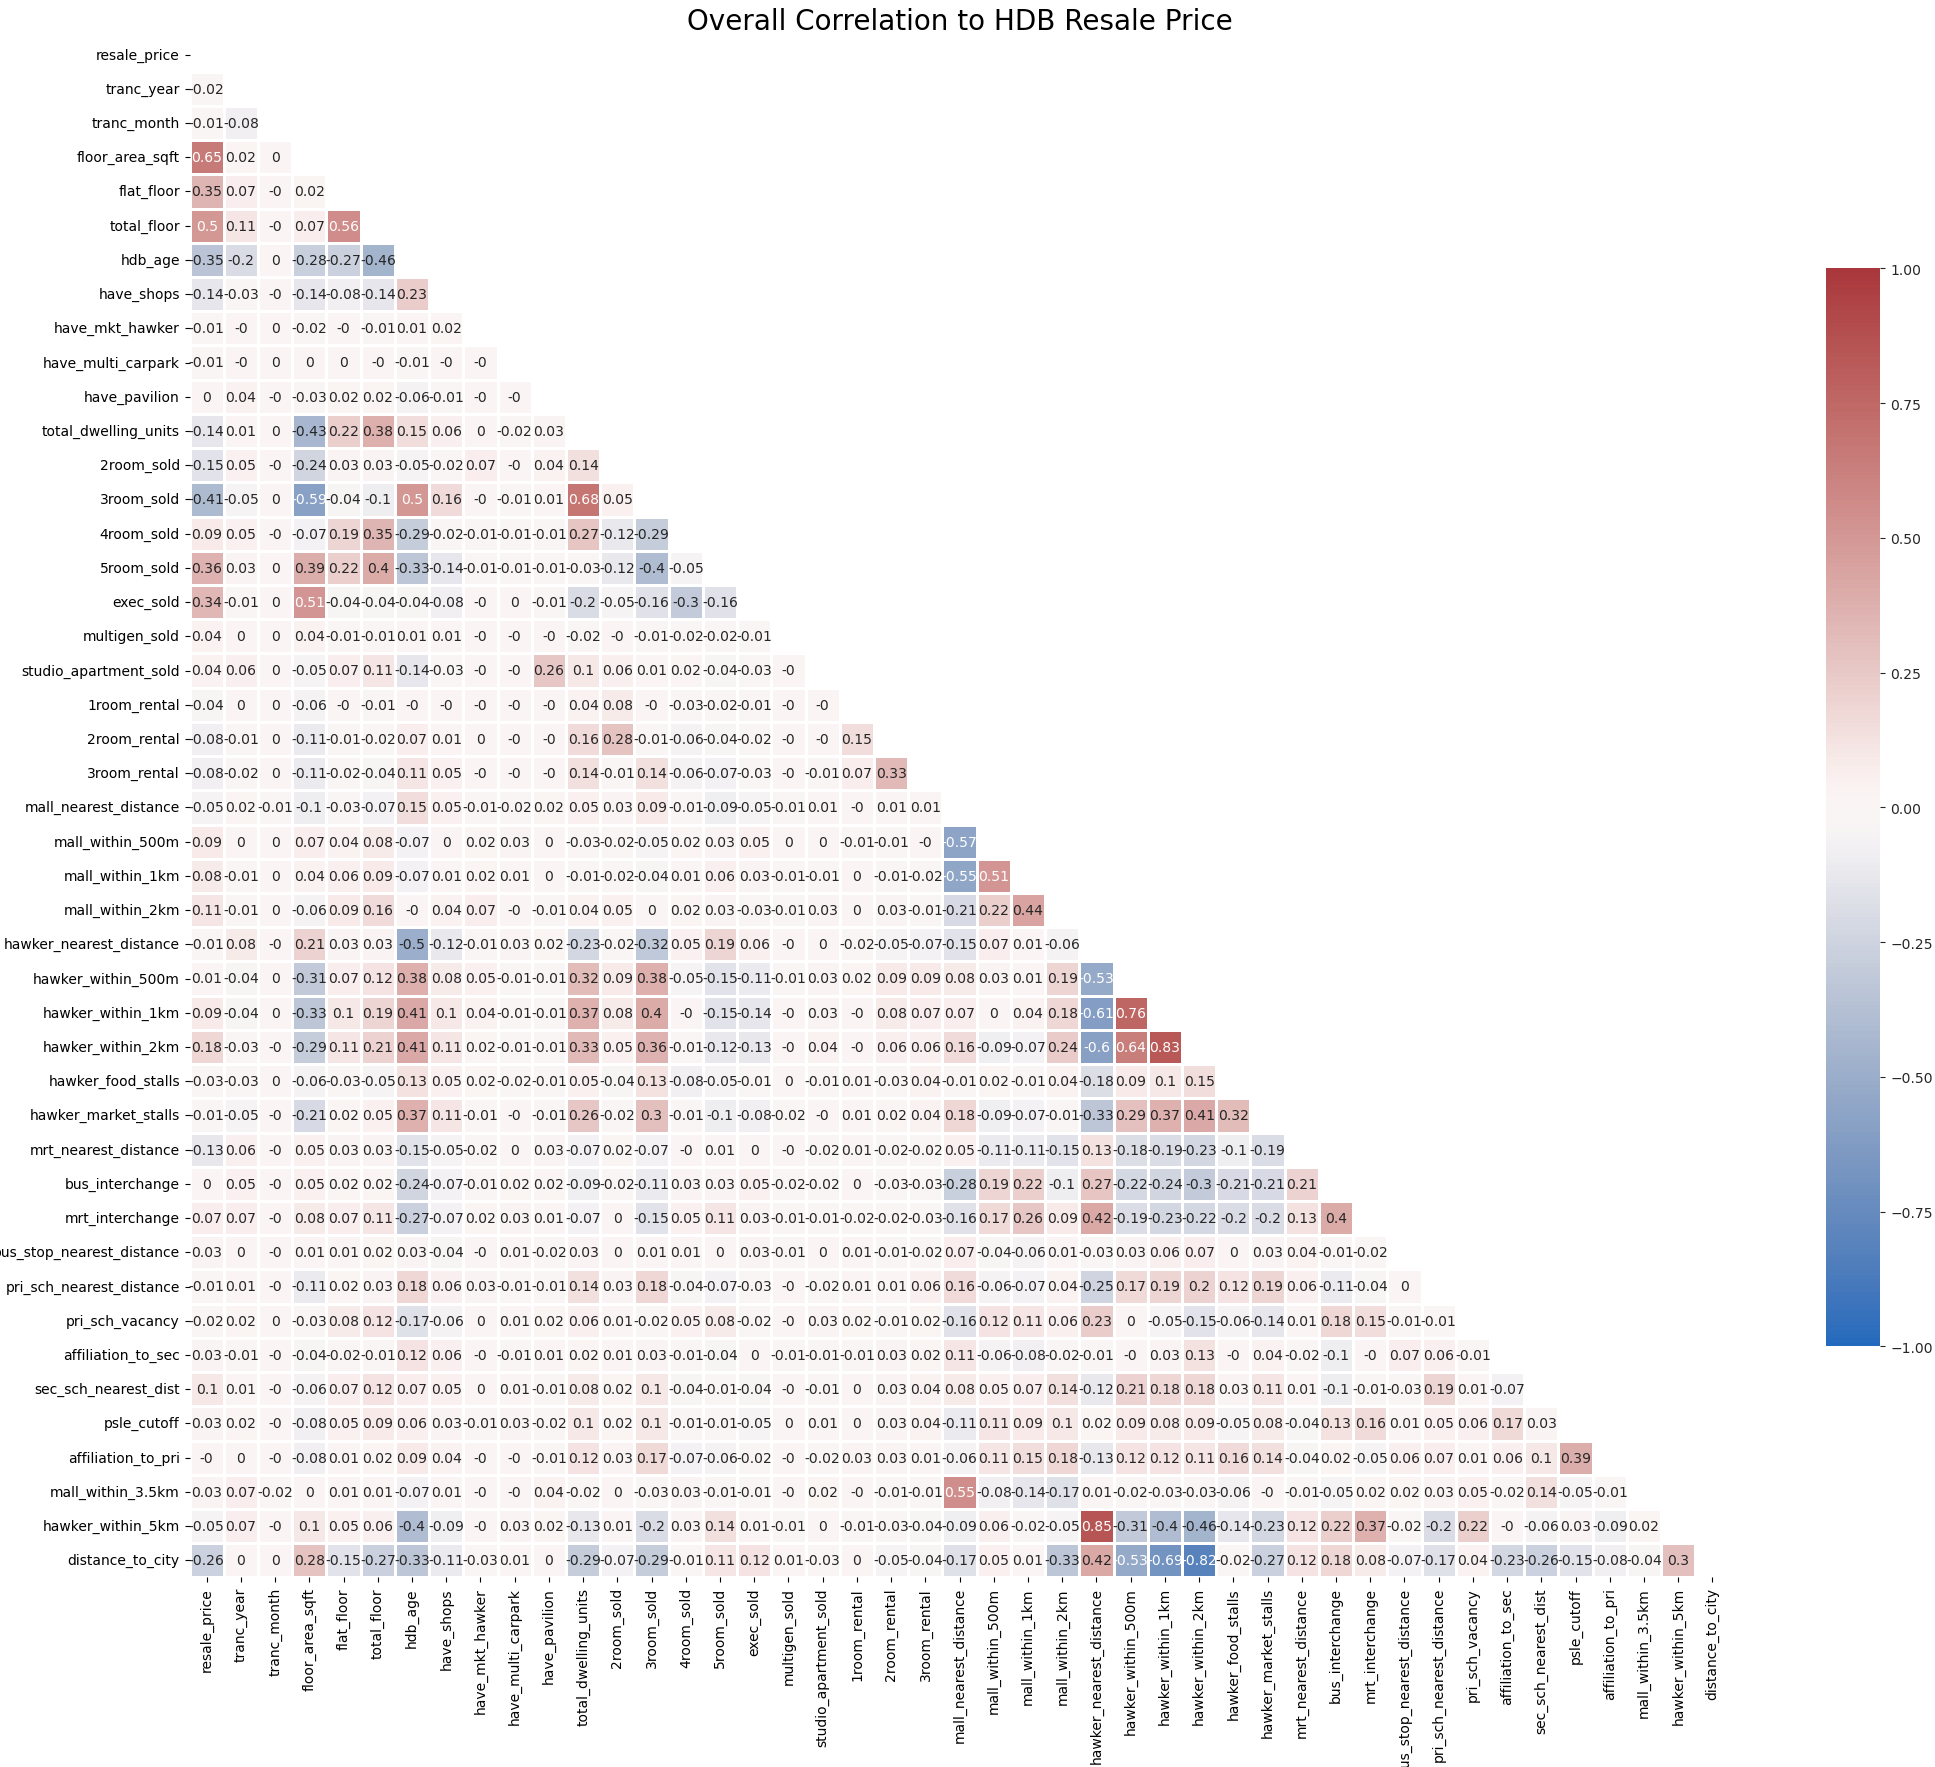

In [38]:
# Define new dataframe that exclude object datatype columns:
hdb_heatmap = hdb.select_dtypes(exclude=['object']).drop('id', axis=1) # remove ID column

# Visualize correlations among variables through a heatmap:
plt.figure(figsize = (25,20))
plt.title('Overall Correlation to HDB Resale Price', fontsize=20)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Get correlation of variables
corr = hdb_heatmap.corr().round(2)

# Generate a mask for the upper triangle to hide unnecesary values
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up color scheme
cmap = sns.color_palette("vlag", as_cmap=True)

# Plot correlation heatmap with mask
with sns.axes_style("white"):
    sns.heatmap(corr, mask = mask, square = True, annot = True, vmin = -1, vmax = 1, linewidths = 1, annot_kws={"size":10}, cbar_kws={"shrink": 0.7}, cmap=cmap);


The top 5 features by strength of correlation to resale price:
* **floor_area_sqft (0.65)**: The logical understanding is that the bigger the flat is, the more expensive it is.
* **total_floor (0.5)**: High rise flats tend to be more expensive and units located at higher floors may possibly fetch a premium.
* **3room_sold (-0.41)**: Negative correlation - blocks with more 3-room flat units tend to consist of smaller flats, which in turn are cheaper. 
* **5room_sold (0.36)**: Related to flat size, the probability of buyers buying a 5-room flat in buildings with more 5-room flat units is relatively higher, and bigger flats naturally cost more.
* **hdb_age (-0.35)**: Negative correlation - the older the flat, the shorter the remaining lease, hence the lower the price.

* Other variables that could be interesting to analyze futher: **flat_floor (0.35)**, **exec_sold (0.34)**, **distance_to_city (-0.26)**

**Price over Time**

In [39]:
# Extract the relevant data
yearly_prices = hdb.groupby('tranc_year')['resale_price'].mean() # Calculate mean resale price for each year
# Divide resale price by flat area to get the price per square foot and calculate mean for each year
yearly_psf = hdb.groupby('tranc_year')['resale_price'].sum() / hdb.groupby('tranc_year')['floor_area_sqft'].sum()
# Calculate the number of flats sold for each flat type per year
yearly_flats = hdb.groupby(['tranc_year', 'flat_type'])['id'].count().unstack()
# Calculate the counts of the top 5 most sold town in each year:
yearly_town = hdb.groupby(['tranc_year', 'town'])['id'].count().groupby('tranc_year').nlargest(5).reset_index(level=0, drop=True).unstack()

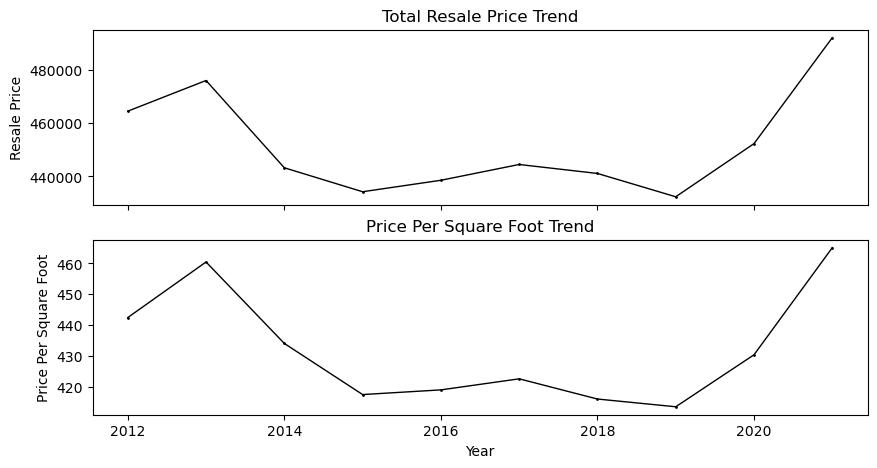

In [40]:
# Create 2 subplots for the two price related line charts
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

# Plot the mean resale price per year
ax1.plot(yearly_prices, color='black', marker='o', linestyle='solid', linewidth=1, markersize=1)
ax1.set_title('Total Resale Price Trend', fontsize=12)
ax1.set_ylabel('Resale Price', fontsize=10)

# Plot the mean price per square foot per year
ax2.plot(yearly_psf, color='black', marker='o', linestyle='solid', linewidth=1, markersize=1)
ax2.set_title('Price Per Square Foot Trend', fontsize=12)
ax2.set_ylabel('Price Per Square Foot', fontsize=10)
ax2.set_xlabel('Year', fontsize=10)

plt.show()

**Comments**

There are two price dips observed between 2013 and 2015, then 2018 as government cooling measures were implemented to slow down property price increase.

**Price Trends by Flat Type**

In [41]:
# Create a new dataframe from hdb
hdb_eda = hdb.loc[:, ['id', 'tranc_year', 'tranc_month', 'town', 'flat_type', 'flat_model', 'floor_area_sqft', 'resale_price']]
# Create a new column for the price per square foot
hdb_eda['price_per_sqft'] = hdb_eda['resale_price'] / hdb_eda['floor_area_sqft']

#convert transcation year and month to datetime
hdb_eda['tranc_year'] = pd.to_datetime(hdb_eda['tranc_year'], format='%Y')
hdb_eda['tranc_month'] = pd.to_datetime(hdb_eda['tranc_month'], format='%m')

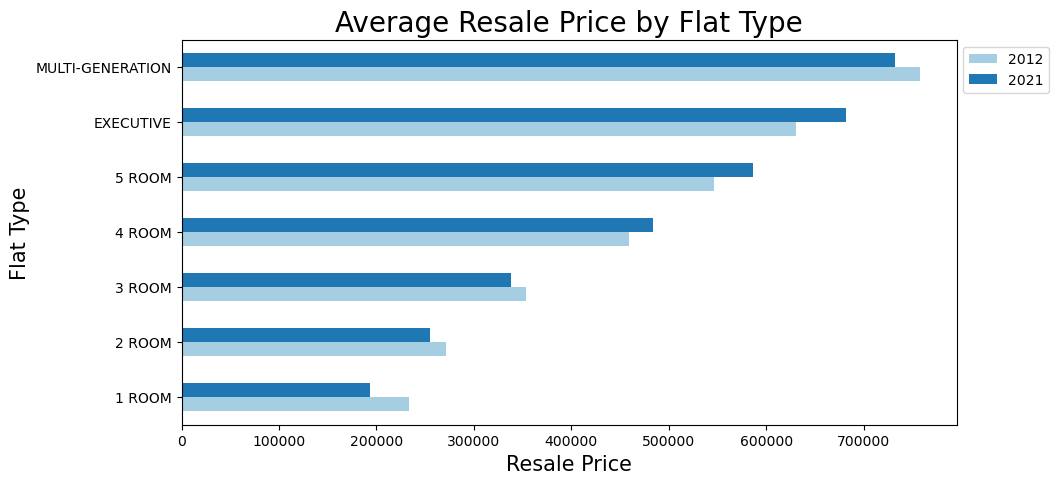

In [42]:
# Define custom color palette
custom_palette = sns.color_palette("Paired")

# Subset the transactions made in 2012 and 2021
hdb_2012 = hdb[hdb['tranc_year'] == 2012]
hdb_2021 = hdb[hdb['tranc_year'] == 2021]

# Calculate the mean resale price for each flat type in 2012 and 2021
mean_price_2012 = hdb_2012.groupby('flat_type')['resale_price'].mean()
mean_price_2021 = hdb_2021.groupby('flat_type')['resale_price'].mean()

# Create a new dataframe for the mean resale price for each flat type in 2012 and 2021
mean_price = pd.DataFrame({'2012': mean_price_2012, '2021': mean_price_2021})

# plot mean resale price in 2012 and mean resale price in 2021 for each flat type as a barh chart
mean_price.plot(kind='barh', figsize=(10, 5), color=custom_palette)
plt.title('Average Resale Price by Flat Type', fontsize=20)
plt.xlabel('Resale Price', fontsize=15)
plt.ylabel('Flat Type', fontsize=15)
plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.show()

**Most Popular Flat Type and Locations Over Time**

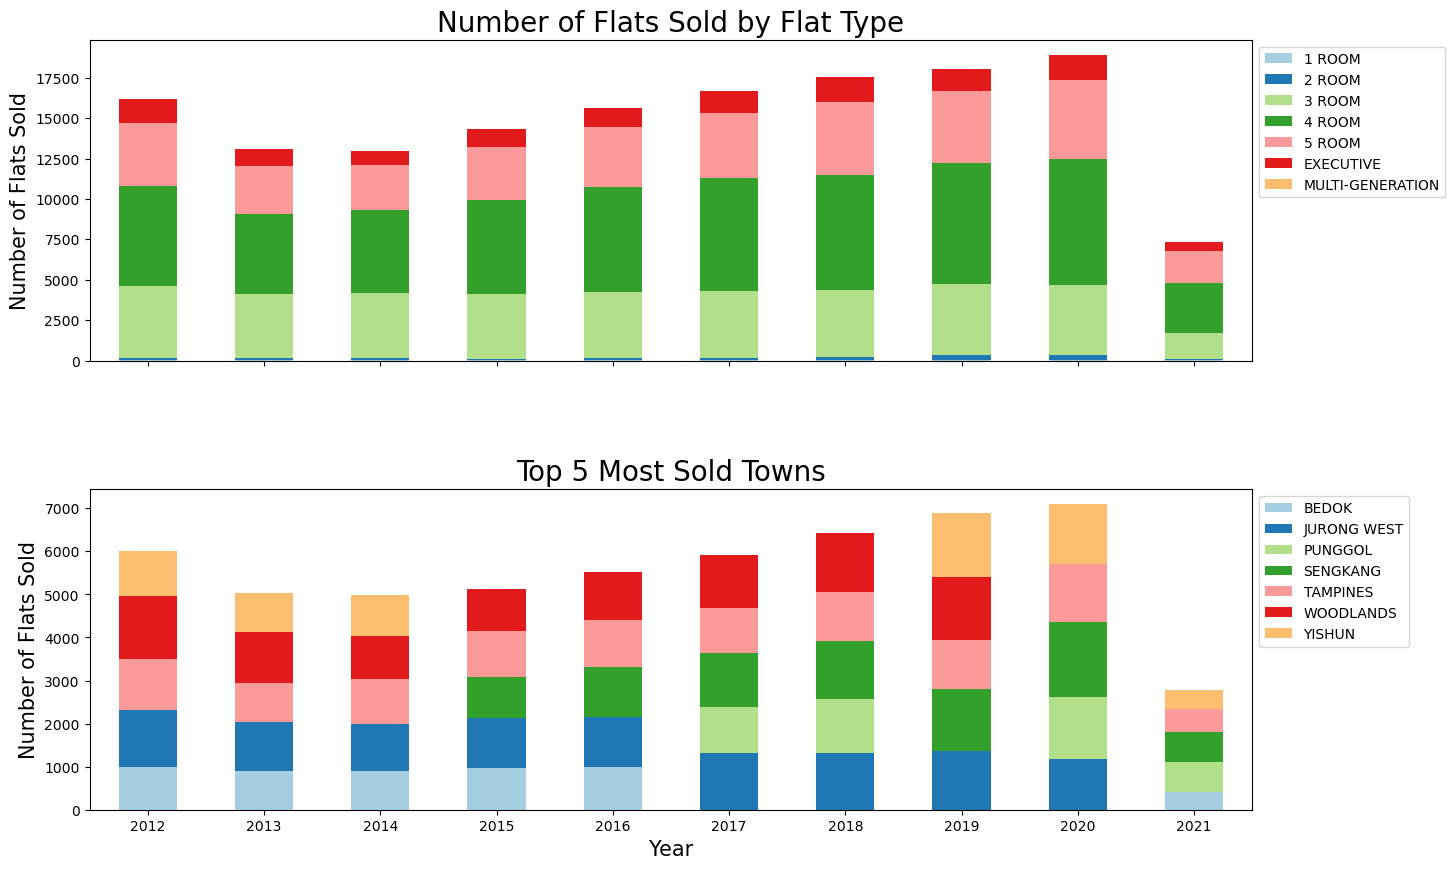

In [43]:
# Create 2 subplots for the two stacked bar charts
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# Plot the number of flats sold for each flat type per year
yearly_flats.plot(kind='bar', stacked=True, ax=ax1, color=custom_palette)
ax1.set_title('Number of Flats Sold by Flat Type', fontsize=20)
ax1.set_ylabel('Number of Flats Sold', fontsize=15)
ax1.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))

# Plot the counts of the top 5 most sold towns in each year
yearly_town.plot(kind='bar', stacked=True, ax=ax2, color=custom_palette)
ax2.set_title('Top 5 Most Sold Towns', fontsize=20)
ax2.set_ylabel('Number of Flats Sold', fontsize=15)
ax2.set_xlabel('Year', fontsize=15)
ax2.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))

# Keep the year labels on the x-axis horizontal
ax2.tick_params(axis='x', labelrotation=0)

# Adjust the layout and spacing between subplots
fig.subplots_adjust(hspace=0.4)

plt.show()

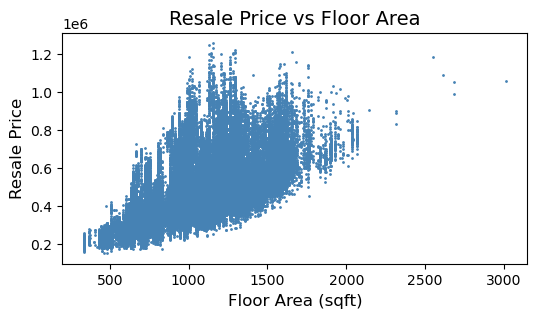

In [44]:
# Scatter plot of resale price vs floor area
plt.figure(figsize=(6, 3))
plt.scatter(hdb_eda['floor_area_sqft'], hdb_eda['resale_price'], color='steelblue', marker='o', s=1)
plt.title('Resale Price vs Floor Area', fontsize=14)
plt.xlabel('Floor Area (sqft)', fontsize=12)
plt.ylabel('Resale Price', fontsize=12)
plt.show()

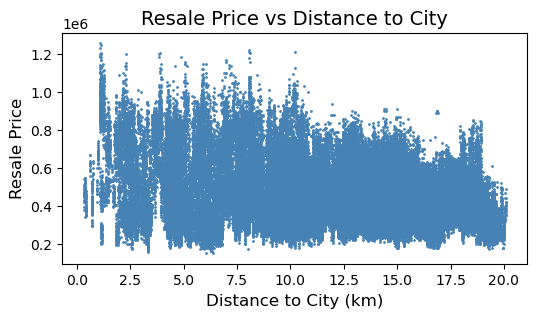

In [45]:
# Scatter plot of resale price vs distance to city (converted from metres to km)
plt.figure(figsize=(6, 3))
plt.scatter(hdb['distance_to_city'] / 1000, hdb['resale_price'], color='steelblue', marker='o', s=1)
plt.title('Resale Price vs Distance to City', fontsize=14)
plt.xlabel('Distance to City (km)', fontsize=12)
plt.ylabel('Resale Price', fontsize=12)
plt.show()

In [46]:
# Define the dependent variable (i.e. the housing prices) and the independent variables
y = hdb['resale_price']
# include only integer and float dtypes
X = hdb.select_dtypes(include=['int64', 'float64']).drop(['resale_price', 'id'], axis=1)

# Add a constant column to the independent variables (required by statsmodels)
X = sm.add_constant(X)

# Fit the OLS regression model and print the results summary
model = sm.OLS(y, X).fit()

# print the top 10
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           resale_price   R-squared:                       0.835
Model:                            OLS   Adj. R-squared:                  0.835
Method:                 Least Squares   F-statistic:                 1.732e+04
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:37:14   Log-Likelihood:            -1.8665e+06
No. Observations:              150634   AIC:                         3.733e+06
Df Residuals:                  150589   BIC:                         3.733e+06
Df Model:                          44                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

In [47]:
# Extract the p-values for each variable
p_values = model.summary().tables[1].data[1:]

# Convert the p-values to a dataframe
results_df = pd.DataFrame(p_values, columns=['Variable', 'coef', 'std err', 't', 'P>|t|', '[0.025', '0.975]'])

# Convert the p-values to numeric values
results_df['P>|t|'] = pd.to_numeric(results_df['P>|t|'], errors='coerce')

# filter for the statistically insignificant variables
results_df[results_df['P>|t|'] > 0.05]

,Variable,coef,std err,t,P>|t|,[0.025,0.975]
8,have_mkt_hawker,-4084.5572,1.52e+04,-0.270,0.788,-3.38e+04,2.56e+04
13,3room_sold,-4.6224,25.546,-0.181,0.856,-54.692,45.447
14,4room_sold,-4.5966,25.839,-0.178,0.859,-55.240,46.047
20,2room_rental,55.6182,29.530,1.883,0.060,-2.259,113.496


In [48]:
# drop the columns above and put in into a new dataframe
hdb_modelling = hdb.drop(['have_mkt_hawker','3room_sold','4room_sold','2room_rental'], axis=1)
hdb_modelling.shape

(150634, 52)

In [49]:
# Export the new dataset to a CSV file:
hdb_modelling.to_csv('../data/hdb_modelling_2.csv', index=False)